## 1. Enviorment and Dataset setup

In [1]:
import sys, importlib

print("python version", sys.version.split()[0])
print('executable', sys.executable)

for pkg in ['numpy', 'pandas', 'matplotlib', 'music21', 'pretty_midi']:
    try:
        m = importlib.import_module(pkg)
        print(f'{pkg:<12}: {m.__version__}')
    except ImportError as e:
        print(f'{pkg} not found: {e}')

python version 3.14.3
executable d:\Projects\fyp\.venv\Scripts\python.exe
numpy       : 2.5.3
pandas      : 3.0.6
matplotlib  : 3.11.2
music21     : 10.5.0
pretty_midi : 0.2.11.post0


In [2]:
import sys, shutil, subprocess, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))

from utils.constants import PROJECT, DATASET_LOCATION,ARTIFACTS_LOCATION
print(PROJECT)

PROJECT.mkdir(exist_ok=True)
ARTIFACTS_LOCATION.mkdir(exist_ok=True, parents=True)
if not (DATASET_LOCATION / 'metadata.csv').exists():
    if shutil.which('git') is None:
        raise RuntimeError(
            'git was not found on PATH. Install Git (https://git-scm.com/downloads), '
            'reopen the terminal, restart the kernel, and re-run this cell.'
        )
    print('Cloning (n)ASAP dataset (shallow clone, a few GB - this takes a few minutes)...')
    subprocess.run(
        ['git', 'clone', '--depth', '1',
         'https://github.com/CPJKU/asap-dataset.git', str(DATASET_LOCATION)],
        check=True,
    )
    print('Clone finished.')
else:
    print('ASAP dataset already on disk - skipping clone.')

print('Project root :', PROJECT)
print('Output base  :', ARTIFACTS_LOCATION)
print('ASAP root    :', DATASET_LOCATION, '| metadata.csv present:', (DATASET_LOCATION / 'metadata.csv').exists())

D:\Projects\fyp
ASAP dataset already on disk - skipping clone.
Project root : D:\Projects\fyp
Output base  : D:\Projects\fyp\artifacts
ASAP root    : D:\Projects\fyp\data\asap-dataset | metadata.csv present: True


In [3]:
metadata = pd.read_csv(DATASET_LOCATION / 'metadata.csv')
print(f"Metadata shape: {metadata.shape}")
print(f"Metadata columns: {metadata.columns.tolist()}")
assert 'robust_note_alignment' in metadata.columns, \
    'robust_note_alignment missing'
metadata.head(3)

Metadata shape: (1066, 17)
Metadata columns: ['composer', 'title', 'folder', 'xml_score', 'midi_score', 'midi_performance', 'performance_annotations', 'midi_score_annotations', 'maestro_midi_performance', 'maestro_audio_performance', 'start', 'end', 'audio_performance', 'robust_note_alignment', 'note_alignments', 'parangonada_data_folder', 'match_file']


,composer,title,folder,xml_score,midi_score,midi_performance,performance_annotations,midi_score_annotations,maestro_midi_performance,maestro_audio_performance,start,end,audio_performance,robust_note_alignment,note_alignments,parangonada_data_folder,match_file
0,Bach,Fugue_bwv_846,Bach/Fugue/bwv_846,Bach/Fugue/bwv_846/xml_score.musicxml,Bach/Fugue/bwv_846/midi_score.mid,Bach/Fugue/bwv_846/Shi05M.mid,Bach/Fugue/bwv_846/Shi05M_annotations.txt,Bach/Fugue/bwv_846/midi_score_annotations.txt,{maestro}/2006/MIDI-Unprocessed_19_R1_2006_01-...,{maestro}/2006/MIDI-Unprocessed_19_R1_2006_01-...,144.567708,NaN,Bach/Fugue/bwv_846/Shi05M.wav,1.0,Bach/Fugue/bwv_846/Shi05M_note_alignments/note...,Bach/Fugue/bwv_846/Shi05M_note_alignments/para...,Bach/Fugue/bwv_846/Shi05M.match
1,Bach,Fugue_bwv_848,Bach/Fugue/bwv_848,Bach/Fugue/bwv_848/xml_score.musicxml,Bach/Fugue/bwv_848/midi_score.mid,Bach/Fugue/bwv_848/Denisova06M.mid,Bach/Fugue/bwv_848/Denisova06M_annotations.txt,Bach/Fugue/bwv_848/midi_score_annotations.txt,{maestro}/2008/MIDI-Unprocessed_02_R1_2008_01-...,{maestro}/2008/MIDI-Unprocessed_02_R1_2008_01-...,69.317708,NaN,Bach/Fugue/bwv_848/Denisova06M.wav,1.0,Bach/Fugue/bwv_848/Denisova06M_note_alignments...,Bach/Fugue/bwv_848/Denisova06M_note_alignments...,Bach/Fugue/bwv_848/Denisova06M.match
2,Bach,Fugue_bwv_848,Bach/Fugue/bwv_848,Bach/Fugue/bwv_848/xml_score.musicxml,Bach/Fugue/bwv_848/midi_score.mid,Bach/Fugue/bwv_848/Lee01M.mid,Bach/Fugue/bwv_848/Lee01M_annotations.txt,Bach/Fugue/bwv_848/midi_score_annotations.txt,{maestro}/2011/MIDI-Unprocessed_08_R1_2011_MID...,{maestro}/2011/MIDI-Unprocessed_08_R1_2011_MID...,74.795573,NaN,Bach/Fugue/bwv_848/Lee01M.wav,1.0,Bach/Fugue/bwv_848/Lee01M_note_alignments/note...,Bach/Fugue/bwv_848/Lee01M_note_alignments/para...,Bach/Fugue/bwv_848/Lee01M.match


In [4]:
print('Unique Pieces:', metadata['folder'].nunique())
print('Total Pieces:', len(metadata))
print('Composers:', metadata['composer'].nunique())
print()
print(metadata['composer'].value_counts())

Unique Pieces: 242
Total Pieces: 1066
Composers: 16

composer
Chopin          289
Beethoven       270
Bach            169
Liszt           121
Schubert         62
Haydn            44
Schumann         28
Ravel            22
Mozart           16
Scriabin         13
Balakirev        10
Prokofiev         8
Rachmaninoff      8
Debussy           3
Glinka            2
Brahms            1
Name: count, dtype: int64


In [5]:
n_before = len(metadata)
clean = metadata[metadata['robust_note_alignment'] == True].copy()
print(f'{n_before} -> {len(clean)} performances '
      f'({n_before - len(clean)} dropped for unreliable alignment)')
print('Pieces remaining:', clean["folder"].nunique())
clean.head(3)

1066 -> 834 performances (232 dropped for unreliable alignment)
Pieces remaining: 187


,composer,title,folder,xml_score,midi_score,midi_performance,performance_annotations,midi_score_annotations,maestro_midi_performance,maestro_audio_performance,start,end,audio_performance,robust_note_alignment,note_alignments,parangonada_data_folder,match_file
0,Bach,Fugue_bwv_846,Bach/Fugue/bwv_846,Bach/Fugue/bwv_846/xml_score.musicxml,Bach/Fugue/bwv_846/midi_score.mid,Bach/Fugue/bwv_846/Shi05M.mid,Bach/Fugue/bwv_846/Shi05M_annotations.txt,Bach/Fugue/bwv_846/midi_score_annotations.txt,{maestro}/2006/MIDI-Unprocessed_19_R1_2006_01-...,{maestro}/2006/MIDI-Unprocessed_19_R1_2006_01-...,144.567708,NaN,Bach/Fugue/bwv_846/Shi05M.wav,1.0,Bach/Fugue/bwv_846/Shi05M_note_alignments/note...,Bach/Fugue/bwv_846/Shi05M_note_alignments/para...,Bach/Fugue/bwv_846/Shi05M.match
1,Bach,Fugue_bwv_848,Bach/Fugue/bwv_848,Bach/Fugue/bwv_848/xml_score.musicxml,Bach/Fugue/bwv_848/midi_score.mid,Bach/Fugue/bwv_848/Denisova06M.mid,Bach/Fugue/bwv_848/Denisova06M_annotations.txt,Bach/Fugue/bwv_848/midi_score_annotations.txt,{maestro}/2008/MIDI-Unprocessed_02_R1_2008_01-...,{maestro}/2008/MIDI-Unprocessed_02_R1_2008_01-...,69.317708,NaN,Bach/Fugue/bwv_848/Denisova06M.wav,1.0,Bach/Fugue/bwv_848/Denisova06M_note_alignments...,Bach/Fugue/bwv_848/Denisova06M_note_alignments...,Bach/Fugue/bwv_848/Denisova06M.match
2,Bach,Fugue_bwv_848,Bach/Fugue/bwv_848,Bach/Fugue/bwv_848/xml_score.musicxml,Bach/Fugue/bwv_848/midi_score.mid,Bach/Fugue/bwv_848/Lee01M.mid,Bach/Fugue/bwv_848/Lee01M_annotations.txt,Bach/Fugue/bwv_848/midi_score_annotations.txt,{maestro}/2011/MIDI-Unprocessed_08_R1_2011_MID...,{maestro}/2011/MIDI-Unprocessed_08_R1_2011_MID...,74.795573,NaN,Bach/Fugue/bwv_848/Lee01M.wav,1.0,Bach/Fugue/bwv_848/Lee01M_note_alignments/note...,Bach/Fugue/bwv_848/Lee01M_note_alignments/para...,Bach/Fugue/bwv_848/Lee01M.match


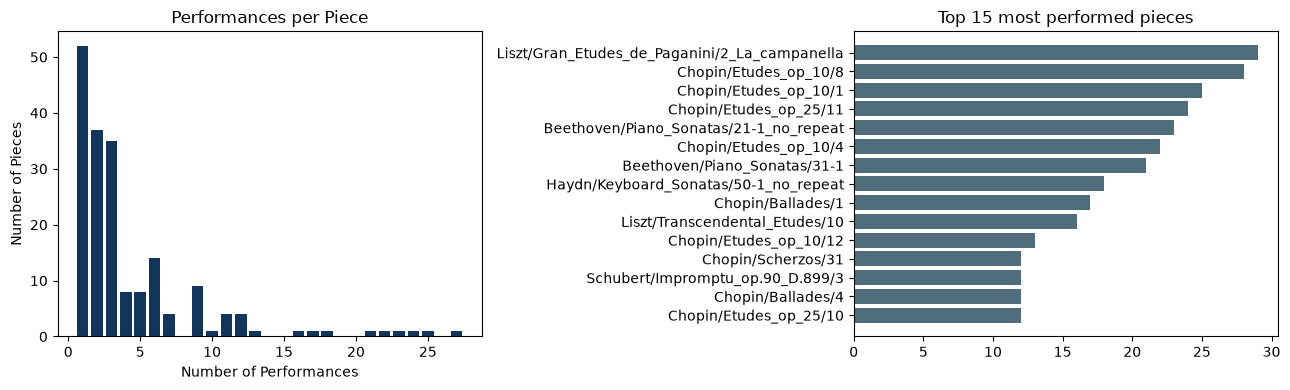

In [6]:
from utils.constants import PRIMARY_COLOR, ACCENT_COLOR

perPiece = clean.groupby('folder').size().sort_values(ascending=False)

fig, axes = plt.subplots(1,2, figsize=(13,4))
axes[0].hist(perPiece, bins=range(1, perPiece.max()),color=PRIMARY_COLOR, align='left', rwidth=0.8)
axes[0].set_title('Performances per Piece')
axes[0].set_xlabel('Number of Performances')
axes[0].set_ylabel('Number of Pieces')


topPieces = perPiece.head(15)
axes[1].barh(topPieces.index, topPieces, color=ACCENT_COLOR)
axes[1].invert_yaxis(); axes[1].set_title('Top 15 most performed pieces')
plt.tight_layout(); plt.show()

In [7]:
from utils.constants import ARTIFACTS_LOCATION

outputDirectory = ARTIFACTS_LOCATION / 'cleaned_metadata.csv'
clean.to_csv(outputDirectory, index=False)
print(f'Saved {len(clean)} rows and {clean["folder"].nunique()} pieces to {outputDirectory}')


Saved 834 rows and 187 pieces to D:\Projects\fyp\artifacts\cleaned_metadata.csv
